# LAB 15 · Mobile application for medical image recognition
**Student:** Rommel Tuquerres

- **Data:** PneumoniaMNIST (MedMNIST v3), chest X-rays, 2 classes: *normal* / *pneumonia*, 128×128 px.
- **Model:** MobileNetV2 (ImageNet) with transfer learning + fine-tuning.
- **Output:** `model.tflite` with metadata for ML Kit Custom Image Labeling (Android).
- **Goal:** test accuracy > 0.7.
- **Environment:** local VS Code, venv `ia_lab15` (TensorFlow on CPU).

## 1. Setup

In [1]:
%pip install -q scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__, "|", tf.config.list_physical_devices())

# Configuration
ALUMNO    = "Rommel_Tuquerres"
PROYECTO  = f"{ALUMNO}_lab15"
IMG_SIZE  = 128   # 128 px: faster CPU training
OUT = Path("outputs"); (OUT / "test_images").mkdir(parents=True, exist_ok=True)
BATCH     = 32
EPOCHS_HEAD = 5   # frozen base
EPOCHS_FT   = 5   # fine-tuning
SEED = 42
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0 | [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Data

In [3]:
# PneumoniaMNIST 128 px from Zenodo (cached in ~/.keras/datasets)
path = tf.keras.utils.get_file(
    "pneumoniamnist_128.npz",
    "https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1",
    file_hash="05b46931834c231683c68f40c47b2971", hash_algorithm="md5")
data = np.load(path)

x_train, y_train = data["train_images"], data["train_labels"].reshape(-1).astype("int32")
x_val,   y_val   = data["val_images"],   data["val_labels"].reshape(-1).astype("int32")
x_test,  y_test  = data["test_images"],  data["test_labels"].reshape(-1).astype("int32")

LABELS = ["normal", "pneumonia"]
NUM_CLASSES = len(LABELS)
GRAY = (x_train.ndim == 3)

print("train:", x_train.shape, "val:", x_val.shape, "test:", x_test.shape)
print("Train distribution:", dict(zip(LABELS, np.bincount(y_train, minlength=NUM_CLASSES))))

75506212/75506212 ━━━━━━━━━━━━━━━━━━━━ 94s 1us/step
train: (4708, 128, 128) val: (524, 128, 128) test: (624, 128, 128)
Train distribution: {'normal': np.int64(1214), 'pneumonia': np.int64(3494)}


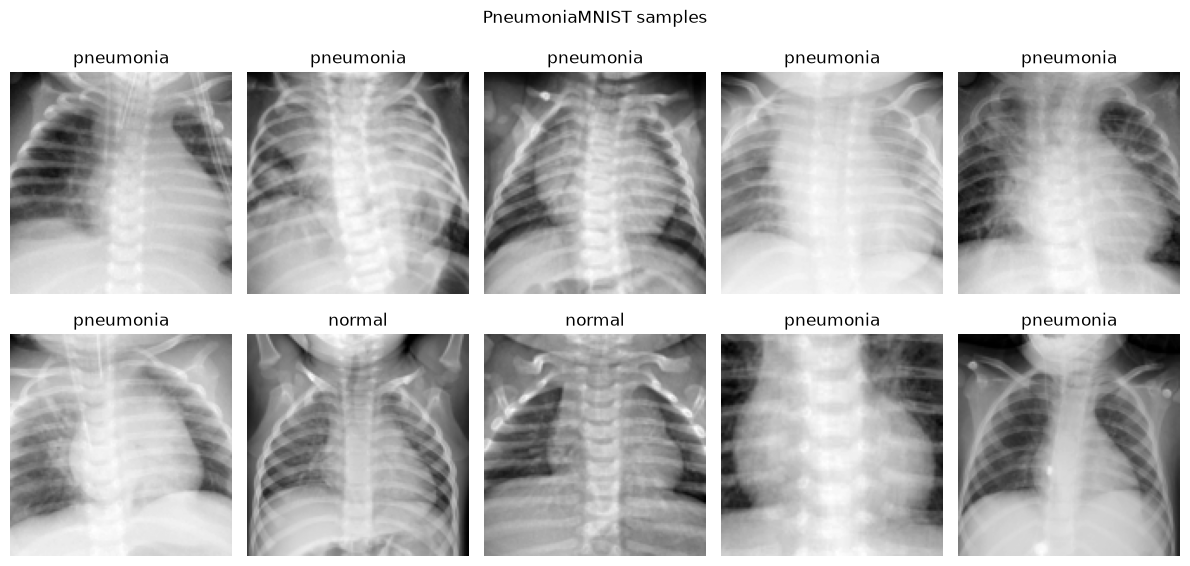

In [4]:
plt.figure(figsize=(12, 6))
for i, idx in enumerate(np.random.default_rng(SEED).choice(len(x_train), 10, replace=False)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[idx], cmap="gray" if GRAY else None)
    plt.title(LABELS[y_train[idx]]); plt.axis("off")
plt.suptitle("PneumoniaMNIST samples"); plt.tight_layout(); plt.show()

## 3. Preprocessing
Normalization `x / 127.5 - 1` (same as ML Kit metadata: mean = std = 127.5). Grayscale → 3 channels.

In [5]:
def prep(x, y):
    x = tf.cast(x, tf.float32)
    if x.shape.rank == 2:
        x = tf.stack([x, x, x], axis=-1)
    x = tf.image.resize(x, (IMG_SIZE, IMG_SIZE))
    x = x / 127.5 - 1.0
    return x, y

augment = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
])

def make_ds(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    ds = ds.map(prep, num_parallel_calls=AUTOTUNE).batch(BATCH)
    if training:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(x_train, y_train, training=True)
val_ds   = make_ds(x_val, y_val)
test_ds  = make_ds(x_test, y_test)

# Class weights (imbalanced data)
counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_weight = {i: len(y_train) / (NUM_CLASSES * c) for i, c in enumerate(counts)}
print("class_weight:", class_weight)

class_weight: {0: np.float64(1.9390444810543657), 1: np.float64(0.6737263880938752)}


## 4. Model

In [6]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs  = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="probability")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability (Dense)             │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Phase 1: train the head
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, class_weight=class_weight)

Epoch 1/5


c:\venvs\ia_lab15\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


148/148 ━━━━━━━━━━━━━━━━━━━━ 42s 239ms/step - accuracy: 0.8611 - loss: 0.3139 - val_accuracy: 0.7519 - val_loss: 0.6455
Epoch 2/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 39s 259ms/step - accuracy: 0.9133 - loss: 0.2139 - val_accuracy: 0.7805 - val_loss: 0.5608
Epoch 3/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 34s 227ms/step - accuracy: 0.9212 - loss: 0.1900 - val_accuracy: 0.8397 - val_loss: 0.4127
Epoch 4/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 33s 221ms/step - accuracy: 0.9261 - loss: 0.1818 - val_accuracy: 0.8912 - val_loss: 0.2602
Epoch 5/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 36s 238ms/step - accuracy: 0.9305 - loss: 0.1826 - val_accuracy: 0.8721 - val_loss: 0.3146


In [8]:
# Phase 2: fine-tune the last 40 layers
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
early = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
hist2 = model.fit(train_ds, validation_data=val_ds,
                  epochs=EPOCHS_HEAD + EPOCHS_FT, initial_epoch=len(hist1.epoch),
                  class_weight=class_weight, callbacks=[early])

Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 56s 305ms/step - accuracy: 0.8989 - loss: 0.4212 - val_accuracy: 0.9370 - val_loss: 0.1592
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 45s 302ms/step - accuracy: 0.9199 - loss: 0.2203 - val_accuracy: 0.9389 - val_loss: 0.1547
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 50s 327ms/step - accuracy: 0.9308 - loss: 0.1766 - val_accuracy: 0.9447 - val_loss: 0.1504
Epoch 9/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 51s 337ms/step - accuracy: 0.9325 - loss: 0.1699 - val_accuracy: 0.9370 - val_loss: 0.1415
Epoch 10/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 53s 354ms/step - accuracy: 0.9359 - loss: 0.1614 - val_accuracy: 0.9447 - val_loss: 0.1310


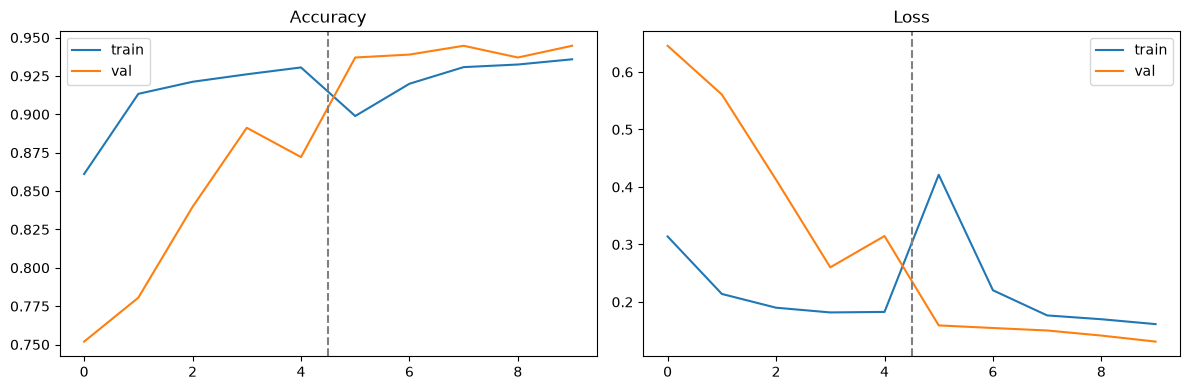

In [9]:
acc  = hist1.history["accuracy"] + hist2.history["accuracy"]
vacc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
loss = hist1.history["loss"] + hist2.history["loss"]
vloss= hist1.history["val_loss"] + hist2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val")
ax[0].axvline(len(hist1.epoch) - 0.5, ls="--", c="gray"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="val")
ax[1].axvline(len(hist1.epoch) - 0.5, ls="--", c="gray"); ax[1].set_title("Loss"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=150); plt.show()

## 5. Model accuracy (test set)

Test accuracy: 0.8317   |   Test loss: 0.5137
              precision    recall  f1-score   support

      normal     0.9510    0.5812    0.7215       234
   pneumonia     0.7963    0.9821    0.8794       390

    accuracy                         0.8317       624
   macro avg     0.8737    0.7816    0.8005       624
weighted avg     0.8543    0.8317    0.8202       624



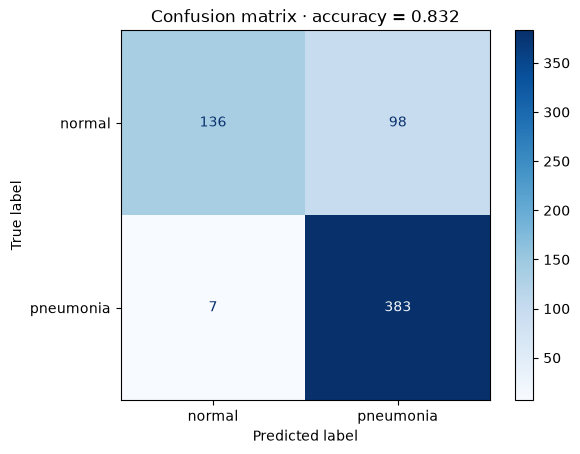

In [10]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

print(f"Test accuracy: {test_acc:.4f}   |   Test loss: {test_loss:.4f}")
print(classification_report(y_test, y_pred, target_names=LABELS, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=LABELS).plot(cmap="Blues")
plt.title(f"Confusion matrix · accuracy = {test_acc:.3f}")
plt.savefig(OUT / "confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Prediction on 4 test images
The same images are used in Android Studio.

img1.jpg  true=normal       pred=pneumonia    probs=[0.295 0.705]
img2.jpg  true=pneumonia    pred=pneumonia    probs=[0. 1.]
img3.jpg  true=normal       pred=pneumonia    probs=[0.1542 0.8458]
img4.jpg  true=pneumonia    pred=pneumonia    probs=[0. 1.]


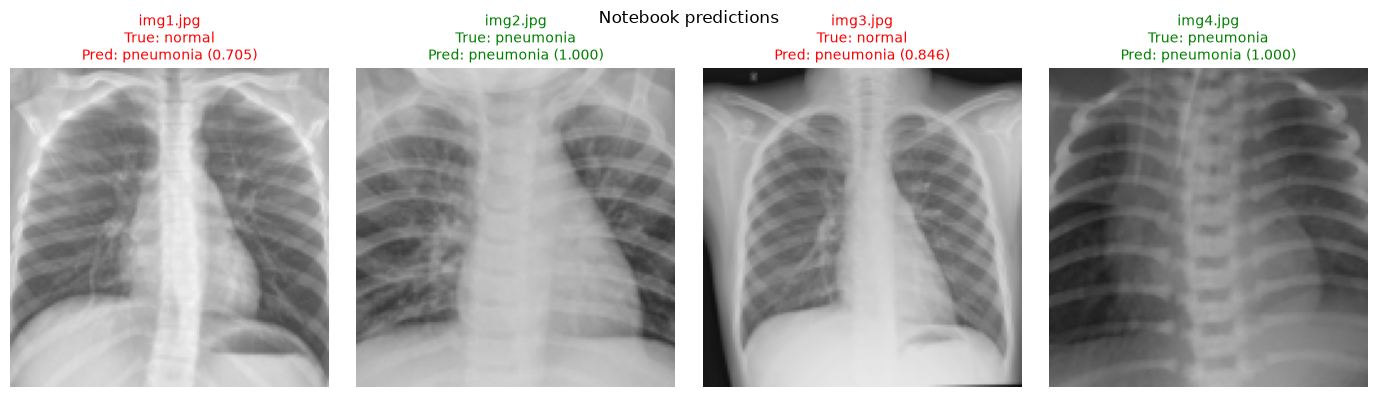

In [11]:
rng = np.random.default_rng(SEED)
per_class = [rng.permutation(np.where(y_test == c)[0]) for c in range(NUM_CLASSES)]
sel = [per_class[k % NUM_CLASSES][k // NUM_CLASSES] for k in range(4)]

TEST_FILES = []
plt.figure(figsize=(14, 4))
for n, idx in enumerate(sel, start=1):
    fname = OUT / "test_images" / f"img{n}.jpg"
    img = Image.fromarray(x_test[idx]).convert("RGB")
    img.save(fname, quality=95)
    TEST_FILES.append(fname)

    p = model.predict(prep(np.array(img), 0)[0][None, ...], verbose=0)[0]
    pred = p.argmax()
    plt.subplot(1, 4, n); plt.imshow(img); plt.axis("off")
    plt.title(f"img{n}.jpg\nTrue: {LABELS[y_test[idx]]}\nPred: {LABELS[pred]} ({p[pred]:.3f})",
              color="green" if pred == y_test[idx] else "red", fontsize=10)
    print(f"img{n}.jpg  true={LABELS[y_test[idx]]:<12} pred={LABELS[pred]:<12} probs={np.round(p, 4)}")
plt.suptitle("Notebook predictions"); plt.tight_layout()
plt.savefig(OUT / "notebook_predictions.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Export to TensorFlow Lite

In [12]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
(OUT / "model_raw.tflite").write_bytes(tflite_model)
(OUT / "labels.txt").write_text("\n".join(LABELS))
print(f"model_raw.tflite: {len(tflite_model)/1e6:.2f} MB")

INFO:tensorflow:Assets written to: C:\Users\royal\AppData\Local\Temp\tmp9gajf6fb\assets


INFO:tensorflow:Assets written to: C:\Users\royal\AppData\Local\Temp\tmp9gajf6fb\assets


Saved artifact at 'C:\Users\royal\AppData\Local\Temp\tmp9gajf6fb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  2706633587984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772083152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772084112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706633588176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706633588560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772083344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772086032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772086224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772085072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2706772082960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  270677208526

## 8. Add ML Kit metadata
`tflite-support` has Windows wheels only up to Python 3.9, so it runs in a separate venv (`C:\venvs\tflite_meta`), created automatically the first time.

In [13]:
META_ENV = Path(r"C:\venvs\tflite_meta")
META_PY  = META_ENV / "Scripts" / "python.exe"

def run(cmd, cwd=None):
    r = subprocess.run([str(c) for c in cmd], cwd=cwd, capture_output=True, text=True)
    print(r.stdout[-1500:], r.stderr[-1500:])
    r.check_returncode()

# One-time setup of the metadata environment
if not META_PY.exists():
    run([sys.executable, "-m", "pip", "install", "-q", "uv"])
    run([sys.executable, "-m", "uv", "venv", "--python", "3.9", META_ENV])
    run([sys.executable, "-m", "uv", "pip", "install", "--python", META_PY, "tflite-support==0.4.3"])

(OUT / "add_metadata.py").write_text("""
from tflite_support.metadata_writers import image_classifier, writer_utils
from tflite_support import metadata

writer = image_classifier.MetadataWriter.create_for_inference(
    writer_utils.load_file("model_raw.tflite"),
    input_norm_mean=[127.5], input_norm_std=[127.5],
    label_file_paths=["labels.txt"])
writer_utils.save_file(writer.populate(), "model.tflite")
print("Associated files:", metadata.MetadataDisplayer.with_model_file("model.tflite").get_packed_associated_file_list())
""")
run([META_PY, "add_metadata.py"], cwd=OUT)

 
 Downloaded cpython-3.9.25-windows-x86_64-none (download)
Using CPython 3.9.25
Creating virtual environment at: C:\venvs\tflite_meta
Activate with: C:\venvs\tflite_meta\Scripts\activate

 Using Python 3.9.25 environment at: C:\venvs\tflite_meta
Resolved 9 packages in 1.68s
 Downloaded numpy
Prepared 9 packages in 4.34s
Installed 9 packages in 510ms
 + absl-py==2.3.1
 + cffi==2.0.0
 + flatbuffers==25.12.19
 + numpy==2.0.2
 + protobuf==3.20.3
 + pybind11==3.1.0
 + pycparser==2.23
 + sounddevice==0.5.6
 + tflite-support==0.4.3

Associated files: ['labels.txt']
 


## 9. TFLite model check

In [14]:
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter
interpreter = Interpreter(model_path=str(OUT / "model.tflite"))
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
print("Entrada:", inp["shape"], inp["dtype"], "| Salida:", out["shape"])

def tflite_predict(batch):
    interpreter.set_tensor(inp["index"], batch.astype(np.float32))
    interpreter.invoke()
    return interpreter.get_tensor(out["index"])[0]

preds = [tflite_predict(prep(x, 0)[0].numpy()[None, ...]).argmax() for x in x_test]
print(f"TFLite test accuracy: {np.mean(np.array(preds) == y_test):.4f}")

for f in TEST_FILES:
    p = tflite_predict(prep(np.array(Image.open(f)), 0)[0].numpy()[None, ...])
    print(f"{f.name:<10} -> {LABELS[p.argmax()]} ({p.max():.4f})")

Entrada: [  1 128 128   3] <class 'numpy.float32'> | Salida: [1 2]


c:\venvs\ia_lab15\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite test accuracy: 0.8317
img1.jpg   -> pneumonia (0.7285)
img2.jpg   -> pneumonia (1.0000)
img3.jpg   -> pneumonia (0.9149)
img4.jpg   -> pneumonia (0.9998)


## 10. Output files
Copy `model.tflite` and `img1.jpg` … `img4.jpg` to `app/src/main/assets` in Android Studio.

In [15]:
for f in sorted(OUT.rglob("*")):
    if f.is_file():
        print(f"{str(f):<40} {f.stat().st_size/1e3:>9.1f} kB")

outputs\add_metadata.py                        0.5 kB
outputs\confusion_matrix.png                  31.8 kB
outputs\labels.txt                             0.0 kB
outputs\model.tflite                        8896.4 kB
outputs\model_raw.tflite                    8895.5 kB
outputs\notebook_predictions.png             131.4 kB
outputs\test_images\img1.jpg                   6.5 kB
outputs\test_images\img2.jpg                   5.7 kB
outputs\test_images\img3.jpg                   5.9 kB
outputs\test_images\img4.jpg                   5.5 kB
outputs\training_curves.png                   80.6 kB


In [1]:
# 11. Extra test set for the Android app (20 random test images + notebook predictions)
import csv
import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter

OUT = Path("outputs")
SET = OUT / "test_set"
SET.mkdir(parents=True, exist_ok=True)
LABELS = ["normal", "pneumonia"]
N_PER_CLASS = 10

# Same cached dataset (no download if it already exists)
path = tf.keras.utils.get_file(
    "pneumoniamnist_128.npz",
    "https://zenodo.org/records/10519652/files/pneumoniamnist_128.npz?download=1",
    file_hash="05b46931834c231683c68f40c47b2971", hash_algorithm="md5")
data = np.load(path)
x_test, y_test = data["test_images"], data["test_labels"].reshape(-1)

# Final model (the same one used in the app)
interp = Interpreter(model_path=str(OUT / "model.tflite"))
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

def predict_jpg(f):
    x = np.asarray(Image.open(f).convert("RGB"), dtype=np.float32) / 127.5 - 1.0
    interp.set_tensor(inp["index"], x[None, ...])
    interp.invoke()
    return interp.get_tensor(out["index"])[0]

# Random sample (fixed seed), 10 per class, mixed order
rng = np.random.default_rng(7)
idxs = np.concatenate([rng.choice(np.where(y_test == c)[0], N_PER_CLASS, replace=False) for c in range(2)])
rng.shuffle(idxs)

rows, correct = [], 0
for n, idx in enumerate(idxs, start=1):
    fname = f"xray_{n:02d}.jpg"
    Image.fromarray(x_test[idx]).convert("RGB").save(SET / fname, quality=95)
    p = predict_jpg(SET / fname)
    true, pred = LABELS[y_test[idx]], LABELS[p.argmax()]
    correct += int(true == pred)
    rows.append([fname, true, pred, f"{p.max():.4f}"])
    print(f"{fname}  true={true:<10} pred={pred:<10} {p.max():.4f}  {'OK' if true == pred else 'X'}")

with open(SET / "labels.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["file", "true", "notebook_pred", "notebook_conf"])
    w.writerows(rows)

print(f"\nNotebook (TFLite) on this set: {correct}/{len(rows)} correct")
print("Saved:", SET.resolve())

c:\venvs\ia_lab15\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


xray_01.jpg  true=pneumonia  pred=pneumonia  1.0000  OK
xray_02.jpg  true=normal     pred=pneumonia  0.9579  X
xray_03.jpg  true=normal     pred=pneumonia  0.9688  X
xray_04.jpg  true=normal     pred=normal     0.5600  OK
xray_05.jpg  true=pneumonia  pred=pneumonia  0.9665  OK
xray_06.jpg  true=pneumonia  pred=pneumonia  1.0000  OK
xray_07.jpg  true=normal     pred=normal     0.8520  OK
xray_08.jpg  true=pneumonia  pred=pneumonia  1.0000  OK
xray_09.jpg  true=normal     pred=normal     0.9797  OK
xray_10.jpg  true=normal     pred=normal     0.9347  OK
xray_11.jpg  true=pneumonia  pred=pneumonia  0.6650  OK
xray_12.jpg  true=pneumonia  pred=pneumonia  1.0000  OK
xray_13.jpg  true=pneumonia  pred=pneumonia  0.9754  OK
xray_14.jpg  true=pneumonia  pred=pneumonia  1.0000  OK
xray_15.jpg  true=normal     pred=pneumonia  0.9815  X
xray_16.jpg  true=normal     pred=pneumonia  0.9522  X
xray_17.jpg  true=pneumonia  pred=pneumonia  0.9974  OK
xray_18.jpg  true=normal     pred=normal     0.9612 